<div dir="rtl" style="text-align:right"><h1>שיעור 3 | איך מודלי שפה עובדים?</h1>
<p>יישומי בינה מלאכותית AI | מחברת להתנסות. <b>אין חובת הגשת מחברת.</b></p>
<p>במחברת נראה ארבעה דברים, כל אחד בסעיף משלו:</p>
<ol>
<li><b>טוקנים</b> – איך <code>tokenizer</code> אמיתי חותך משפט בעברית ובאנגלית ליחידות.</li>
<li><b>חיזוי הטוקן הבא</b> – הסתברויות אמיתיות ממודל שפה פתוח וקטן, ואיך ההקשר משנה אותן.</li>
<li><b>קשב</b> – <b>המחשה רעיונית</b> בלבד, עם מספרים שנבחרו ביד. זו לא מדידה.</li>
<li><b>השלמה שוטפת אינה עובדה</b> – המודל ממציא שעת איסוף שלא נמסרה, ובדיקה פשוטה שתופסת את זה.</li>
</ol>
<h2>איך מריצים</h2>
<p>מריצים תא בלחיצה על ▶ שליד התא, תא אחרי תא לפי הסדר. מעבד רגיל (<code>CPU</code>) מספיק. אין צורך ב-<code>GPU</code>, במפתח <code>API</code> או במנוי בתשלום. בסעיף 2 המחברת מורידה מודל פתוח בגודל של כ-1GB; ההורדה לוקחת בדרך כלל דקה או שתיים.</p>
<p>אם מופיעה אזהרה על <code>HF_TOKEN</code> – אפשר להתעלם ממנה. המודל ציבורי ואין צורך בחשבון.</p></div>

In [1]:
# Setup: tiktoken is the open-source tokenizer library OpenAI publishes.
# transformers and torch are already installed on Google Colab.
%pip install -q tiktoken

import math
import tiktoken
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

print("tiktoken", tiktoken.__version__, "| transformers", transformers.__version__, "| torch", torch.__version__)
print("Setup done")

Note: you may need to restart the kernel to use updated packages.


/tmp/claude-0/-home-user-course-grader/4eb99081-e190-5db8-8aef-eee71b358d51/scratchpad/colabenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


tiktoken 0.14.0 | transformers 5.22.1 | torch 2.15.0+cpu
Setup done


<div dir="rtl" style="text-align:right"><h2>1 | טוקנים: מה המודל מקבל בפועל</h2>
<p>מודל שפה לא מקבל אותיות או מילים, אלא רצף של <b>טוקנים</b>: חתיכות טקסט מתוך אוצר קבוע. את החיתוך עושה <b>tokenizer</b>. טוקן יכול להיות מילה שלמה, חלק ממילה, אות אחת – ולפעמים אפילו חצי אות (חלק מהבתים שמייצגים אות במחשב).</p>
<p>נבדוק שלושה <code>tokenizer</code>-ים אמיתיים, כל אחד בשמו:</p>
<ul>
<li><code>o200k_base</code> – הקידוד ש-OpenAI פרסמה בספריית <code>tiktoken</code> ומשמש חלק מהמודלים החדשים שלה.</li>
<li><code>cl100k_base</code> – קידוד ותיק יותר מאותה ספרייה.</li>
<li><code>Qwen2.5</code> – ה-<code>tokenizer</code> של המודל הפתוח שנשתמש בו בסעיף 2.</li>
</ul>
<p><b>חשוב:</b> אלה מדידות אמיתיות של שלושת ה-<code>tokenizer</code>-ים האלה בלבד. הצ׳טבוט שאתם משתמשים בו עשוי להשתמש ב-<code>tokenizer</code> אחר, ולכן המספרים אצלו יכולים להיות שונים.</p>
<blockquote>לפני ההרצה: נחשו – למשפט «מיכל רוצה שלוש עוגיות למחר» יהיו יותר טוקנים או פחות מאשר לתרגום שלו לאנגלית?</blockquote></div>

In [2]:
TOKENIZERS = {
    "o200k_base": tiktoken.get_encoding("o200k_base"),
    "cl100k_base": tiktoken.get_encoding("cl100k_base"),
    "Qwen2.5": AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B"),
}


def pieces(name, text):
    """The token pieces of `text` under one tokenizer. A piece that is only
    part of a letter's bytes cannot be shown on its own and prints as �."""
    tok = TOKENIZERS[name]
    if name == "Qwen2.5":
        ids = tok.encode(text)
        return [tok.decode([i]) for i in ids]
    ids = tok.encode(text)
    return [tok.decode_single_token_bytes(i).decode("utf-8", errors="replace") for i in ids]


def show_tokens(text):
    print("Text:", text)
    for name in TOKENIZERS:
        parts = pieces(name, text)
        print(f"  {name:12} {len(parts):3} tokens:  " + " | ".join(p.replace(" ", "·") for p in parts))
    print()


show_tokens("מיכל רוצה שלוש עוגיות למחר")
show_tokens("Michal wants three cookies for tomorrow")
print("· marks a space that belongs to the token.  � marks part of a letter (a piece of its bytes).")

Text: מיכל רוצה שלוש עוגיות למחר
  o200k_base    11 tokens:  מ | יכ | ל | ·רוצה | ·של | וש | ·ע | וג | יות | ·למ | חר
  cl100k_base   24 tokens:  מ | י� | � | ל | ·� | � | ו� | � | ה | ·ש | ל | ו� | � | ·� | � | ו� | � | י | ו� | � | ·ל | מ | ח | ר
  Qwen2.5       11 tokens:  מ | יכ | ל | ·רוצה | ·של | וש | ·ע | וג | יות | ·למ | חר

Text: Michal wants three cookies for tomorrow
  o200k_base     7 tokens:  Mich | al | ·wants | ·three | ·cookies | ·for | ·tomorrow
  cl100k_base    7 tokens:  Mich | al | ·wants | ·three | ·cookies | ·for | ·tomorrow
  Qwen2.5        7 tokens:  Mich | al | ·wants | ·three | ·cookies | ·for | ·tomorrow

· marks a space that belongs to the token.  � marks part of a letter (a piece of its bytes).


<div dir="rtl" style="text-align:right"><h3>1א | אותו תוכן, שתי שפות</h3>
<p>התא הבא סופר טוקנים לכמה זוגות של משפטים עם אותו תוכן בעברית ובאנגלית. שימו לב לעמודת היחס: כמה טוקנים בעברית על כל טוקן באנגלית.</p></div>

In [3]:
PAIRS = [
    ("מיכל רוצה שלוש עוגיות למחר", "Michal wants three cookies for tomorrow"),
    ("שעת האיסוף עדיין לא סוכמה", "The pickup time has not been agreed yet"),
    ("בבוקר, לפני העבודה, אני שותה כוס קפה", "In the morning, before work, I drink a cup of coffee"),
]

print(f"{'tokenizer':12} {'Hebrew':>7} {'English':>8} {'ratio':>6}")
for name in TOKENIZERS:
    he = sum(len(pieces(name, h)) for h, _ in PAIRS)
    en = sum(len(pieces(name, e)) for _, e in PAIRS)
    print(f"{name:12} {he:7} {en:8} {he / en:6.2f}")

tokenizer     Hebrew  English  ratio
o200k_base        35       28   1.25
cl100k_base       81       28   2.89
Qwen2.5           36       28   1.29


<div dir="rtl" style="text-align:right"><h3>1ב | התור שלכם</h3>
<p>כתבו בין המירכאות משפט משלכם – למשל הודעה קצרה של לקוח – והריצו. נסו גם מילה עם תחילית («ובבית», «כשהגעתי»), מספר («3») ושם פרטי.</p>
<blockquote>שאלות לחשיבה (לא לבדיקה): איפה ה-<code>tokenizer</code> חתך מילה לחלקים? מה קורה למספר? למה זה משנה – לכמות הטקסט שמודל מקבל בבת אחת (<b>חלון ההקשר</b>) יש גבול שנמדד בטוקנים, ובשירותים בתשלום המחיר נקבע לרוב לפי מספר הטוקנים.</blockquote></div>

In [4]:
my_text = "דנה: למחר בשעה 09:00, ארבע לחמניות ושתי עוגיות."  # <- change this text and run again
show_tokens(my_text)

Text: דנה: למחר בשעה 09:00, ארבע לחמניות ושתי עוגיות.
  o200k_base    22 tokens:  ד | נה | : | ·למ | חר | ·בש | עה | · | 09 | : | 00 | , | ·ארבע | ·לח | מ | ניות | ·וש | תי | ·ע | וג | יות | .
  cl100k_base   41 tokens:  ד | נ | ה | : | ·ל | מ | ח | ר | ·ב | ש | ע | ה | · | 09 | : | 00 | , | ·א | ר | ב | ע | ·ל | ח | מ | נ | י | ו� | � | ·� | � | ש | ת | י | ·� | � | ו� | � | י | ו� | � | .
  Qwen2.5       24 tokens:  ד | נה | : | ·למ | חר | ·בש | עה | · | 0 | 9 | : | 0 | 0 | , | ·אר | בע | ·לח | מניות | ·וש | תי | ·ע | וג | יות | .



<div dir="rtl" style="text-align:right"><h2>2 | חיזוי הטוקן הבא</h2>
<p>מודל שפה מקבל את רצף הטוקנים – <b>ההקשר</b> – ומחשב לכל טוקן אפשרי באוצר שלו הסתברות להיות הטוקן הבא. אחר כך נבחר טוקן אחד, מצורף לרצף, והחישוב חוזר. כך נבנית תשובה שלמה, טוקן אחרי טוקן.</p>
<p>נשתמש במודל הפתוח <code>Qwen/Qwen2.5-0.5B</code>: כחצי מיליארד פרמטרים, גרסת בסיס (לא צ׳טבוט), שרץ על מעבד רגיל. <b>ההגבלות, ביושר:</b></p>
<ul>
<li>זה <b>לא</b> המודל של הצ׳טבוט שלכם. מודלים של צ׳טבוטים גדולים ממנו פי עשרות ומאות, ועברו אימון נוסף לשיחה.</li>
<li>הוא חלש בעברית בהרבה מאשר באנגלית. לכן נריץ כל דוגמה בשתי השפות.</li>
<li>המספרים מראים מה <b>המודל הזה</b> מחשב. הם לא מודדים מה קורה בתוך הצ׳טבוט.</li>
</ul>
<p>במהלך החיזוי <b>הפרמטרים של המודל לא משתנים</b>. מה שמשתנה בין דוגמה לדוגמה הוא רק ההקשר.</p></div>

In [5]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
tokenizer = TOKENIZERS["Qwen2.5"]
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32)
model.eval()
print(f"Loaded {MODEL_NAME}: {sum(p.numel() for p in model.parameters()) / 1e9:.2f} billion parameters")


def next_token_table(context, k=8):
    """The k most likely next tokens after `context`, with probabilities."""
    ids = tokenizer(context, return_tensors="pt").input_ids
    with torch.no_grad():
        probs = torch.softmax(model(ids).logits[0, -1], dim=-1)
    values, indices = probs.topk(k)
    print("Context:", context)
    for p, i in zip(values.tolist(), indices.tolist()):
        piece = tokenizer.decode([i]).replace(" ", "·").replace("\n", "\\n")
        print(f"  {piece:>12}  {p:6.1%}  " + "█" * round(p * 40))
    print()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:00<01:14,  3.88it/s]

Loading weights:  27%|██▋       | 77/290 [00:00<00:00, 258.93it/s]

Loading weights:  40%|████      | 116/290 [00:00<00:00, 227.42it/s]

Loading weights:  50%|█████     | 146/290 [00:00<00:00, 232.74it/s]

Loading weights:  60%|██████    | 174/290 [00:00<00:00, 189.21it/s]

... (3 outputs left out)

Loading weights:  91%|█████████ | 263/290 [00:01<00:00, 179.33it/s]

Loading weights:  97%|█████████▋| 282/290 [00:01<00:00, 179.78it/s]

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 191.27it/s]

Loaded Qwen/Qwen2.5-0.5B: 0.49 billion parameters


<div dir="rtl" style="text-align:right"><h3>2א | אותה התחלה, הקשר אחר</h3>
<p>שני משפטים באנגלית שמסתיימים כמעט באותו אופן. רק תחילת המשפט שונה. הסתכלו על הטוקנים המובילים בכל אחד.</p></div>

In [6]:
next_token_table("Every morning before work I drink a cup of")
next_token_table("At the festive dinner we drank a glass of")

Context: Every morning before work I drink a cup of
       ·coffee   45.5%  ██████████████████
          ·tea   15.4%  ██████
          ·hot    6.8%  ███
        ·green    5.8%  ██
       ·herbal    3.4%  █
             ·    1.8%  █
        ·black    1.4%  █
        ·water    1.1%  



Context: At the festive dinner we drank a glass of
         ·wine   18.0%  ███████
    ·champagne    6.6%  ███
         ·beer    3.8%  ██
       ·orange    3.4%  █
        ·brand    2.6%  █
         ·milk    2.5%  █
          ·rum    2.3%  █
        ·lemon    2.3%  █



<div dir="rtl" style="text-align:right"><h3>2ב | ובעברית?</h3>
<p>אותה דוגמה בעברית. שימו לב: רבים מהטוקנים המובילים הם <b>חלקי מילים</b> – בדיוק מה שראינו בסעיף 1. כדי להשוות מילים שלמות, התא שאחריו מחשב לכל מילה מועמדת את ההסתברות של כל הטוקנים שלה ברצף, ומציג איזה <b>חלק</b> מקבלת כל מילה <b>מתוך המועמדות שבחרנו בלבד</b>. זה לא ההסתברות מכל ההמשכים האפשריים.</p></div>

In [7]:
next_token_table("בבוקר, לפני העבודה, אני שותה כוס")
next_token_table("בערב, עם הארוחה החגיגית, שתינו כוס")

Context: בבוקר, לפני העבודה, אני שותה כוס
             ה   15.8%  ██████
           ·של    5.5%  ██
            ·ח    3.5%  █
            ·ק    3.2%  █
            ות    3.1%  █
            ים    2.3%  █
            ·ש    2.2%  █
            ·ב    2.1%  █

Context: בערב, עם הארוחה החגיגית, שתינו כוס
             ה   11.9%  █████
            ות    9.8%  ████
            ים    7.4%  ███
           ·של    3.0%  █
             י    2.2%  █
            ·מ    1.4%  █
            ·ח    1.4%  █
            ·ו    1.3%  █



In [8]:
def compare_words(context, words):
    """Each candidate word's share among `words` only, from the model's
    probability of all its tokens after `context`."""
    context_ids = tokenizer(context).input_ids
    log_probs = {}
    for word in words:
        word_ids = tokenizer(" " + word).input_ids
        ids = torch.tensor([context_ids + word_ids])
        with torch.no_grad():
            lp = torch.log_softmax(model(ids).logits[0], dim=-1)
        log_probs[word] = sum(lp[len(context_ids) - 1 + j, t].item() for j, t in enumerate(word_ids))
    total = sum(math.exp(v) for v in log_probs.values())
    print("Context:", context)
    for word, v in sorted(log_probs.items(), key=lambda kv: -kv[1]):
        share = math.exp(v) / total
        print(f"  {word:>8}  {share:6.1%}  " + "█" * round(share * 40))
    print()


compare_words("Every morning before work I drink a cup of", ["coffee", "tea", "water", "wine"])
compare_words("At the festive dinner we drank a glass of", ["coffee", "tea", "water", "wine"])
compare_words("בבוקר, לפני העבודה, אני שותה כוס", ["קפה", "תה", "מים", "יין"])
compare_words("בערב, עם הארוחה החגיגית, שתינו כוס", ["קפה", "תה", "מים", "יין"])

Context: Every morning before work I drink a cup of
    coffee   73.3%  █████████████████████████████
       tea   24.9%  ██████████
     water    1.8%  █
      wine    0.0%  



Context: At the festive dinner we drank a glass of
      wine   89.1%  ████████████████████████████████████
       tea    5.2%  ██
     water    3.8%  ██
    coffee    1.9%  █



Context: בבוקר, לפני העבודה, אני שותה כוס
       מים   56.9%  ███████████████████████
       קפה   35.9%  ██████████████
       יין    6.5%  ███
        תה    0.7%  



Context: בערב, עם הארוחה החגיגית, שתינו כוס
       מים   75.6%  ██████████████████████████████
       קפה   14.0%  ██████
       יין    9.3%  ████
        תה    1.2%  



<div dir="rtl" style="text-align:right"><p><b>איך קוראים את התוצאות:</b> באנגלית ההקשר הזיז את ההסתברויות בבירור – משקה של בוקר מול משקה של ארוחה חגיגית. בעברית, בהרצה שלנו, ההזזה הייתה חלשה הרבה יותר, ו«מים» הוביל בשני ההקשרים. זו לא תקלה במחברת: זה מודל קטן שלמד מעט עברית. צ׳טבוט גדול יתנהג אחרת, ואת זה המחברת לא מודדת.</p>
<p>המספרים אצלכם עשויים להיות מעט שונים (גרסאות ספריות שונות), אבל הכיוון אמור להישמר.</p></div>

<div dir="rtl" style="text-align:right"><h3>2ג | התור שלכם</h3>
<p>שנו את ההקשר או את המילים המועמדות והריצו. נסו לשנות <b>פרט אחד בלבד</b> בהקשר בכל פעם, ובדקו מה זז.</p>
<blockquote>שאלות לחשיבה: מה השתנה בין שתי ההרצות – המודל או ההקשר? האם הסתברות גבוהה אומרת שההמשך <b>נכון</b>, או רק שהוא <b>סביר</b> לפי מה שהמודל למד?</blockquote></div>

In [9]:
compare_words("The bakery opens early, and every morning it sells fresh", ["bread", "cookies", "pizza", "ice cream"])  # <- change and run

# The same in Hebrew. The small model is much weaker in Hebrew, so expect odd results:
# compare_words("המאפייה נפתחת מוקדם, ובכל בוקר מוכרים בה", ["לחם", "עוגיות", "פיצה", "גלידה"])

Context: The bakery opens early, and every morning it sells fresh
     bread   99.3%  ████████████████████████████████████████
   cookies    0.7%  
     pizza    0.0%  
  ice cream    0.0%  



<div dir="rtl" style="text-align:right"><h2>3 | קשב: המחשה רעיונית בלבד</h2>
<p>המילה «קפה» יכולה להיות משקה («שתיתי קפה עם חלב») או מקום («נפגשנו בקפה ליד התחנה»). כדי לבנות ייצוג מתאים לטוקן, המודל מחשב <b>כמה משקל לתת לכל טוקן אחר ברצף</b>. החישוב הזה נקרא <b>קשב</b> (<code>attention</code>). במודל כמו שלנו, כל טוקן «מסתכל» רק על הטוקנים שלפניו ועל עצמו.</p>
<p><b>⚠ המספרים בתא הבא נבחרו ביד כדי להמחיש את הרעיון.</b> הם לא נמדדו מתוך מודל כלשהו, ובטח שלא מתוך הצ׳טבוט שאתם משתמשים בו. במודל אמיתי יש עשרות «ראשי קשב» בכל שכבה ועשרות שכבות, והם לא מתחלקים יפה למילים.</p></div>

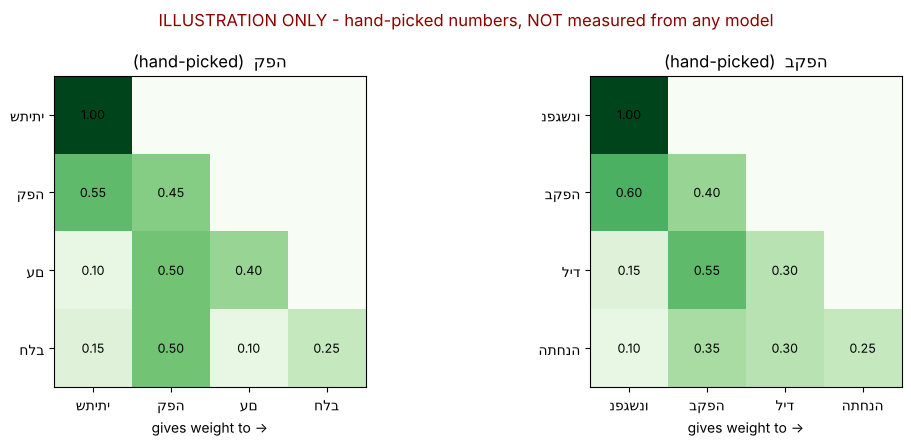

In [10]:
import matplotlib.pyplot as plt


def rtl(word):
    # matplotlib draws text left to right; reversing a Hebrew word displays it correctly.
    return word[::-1]


# ILLUSTRATION: hand-picked numbers, NOT measured from any model.
# Row = the word being represented; columns = how much weight it gives each word
# up to and including itself (each row sums to 1; later words get no weight).
ILLUSTRATIONS = {
    "שתיתי קפה עם חלב": [
        [1.00, 0.00, 0.00, 0.00],
        [0.55, 0.45, 0.00, 0.00],
        [0.10, 0.50, 0.40, 0.00],
        [0.15, 0.50, 0.10, 0.25],
    ],
    "נפגשנו בקפה ליד התחנה": [
        [1.00, 0.00, 0.00, 0.00],
        [0.60, 0.40, 0.00, 0.00],
        [0.15, 0.55, 0.30, 0.00],
        [0.10, 0.35, 0.30, 0.25],
    ],
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (sentence, weights) in zip(axes, ILLUSTRATIONS.items()):
    words = sentence.split()
    ax.imshow(weights, cmap="Greens", vmin=0, vmax=1)
    ax.set_xticks(range(len(words)), [rtl(w) for w in words])
    ax.set_yticks(range(len(words)), [rtl(w) for w in words])
    for r, row in enumerate(weights):
        for c, value in enumerate(row):
            if c <= r:
                ax.text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xlabel("gives weight to ->")
    ax.set_title(rtl(sentence.split()[1]) + "  (hand-picked)")
fig.suptitle("ILLUSTRATION ONLY - hand-picked numbers, NOT measured from any model", color="darkred")
plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align:right"><p>איך קוראים את האיור: כל <b>שורה</b> היא מילה שהמודל בונה לה ייצוג; כל <b>עמודה</b> היא מילה שהיא «מסתכלת» עליה. בשורה של «קפה» במשפט הראשון, המשקל הגבוה הוא על «שתיתי» – רמז למשקה. במשפט השני, «בקפה» נשען על «נפגשנו» – רמז למקום. (המילים בציר מוצגות משמאל לימין, כמו שהספרייה מציירת.)</p>
<p><b>מה האיור לא אומר:</b> שהמודל «מבין» כמו אדם, או שקשר שנלמד הוא עובדה נכונה. קשב הוא חישוב שעוזר לבנות ייצוג לפי ההקשר – לא מקור אמת.</p></div>

<div dir="rtl" style="text-align:right"><h2>4 | השלמה שוטפת אינה עובדה</h2>
<p>ההודעה «מיכל רוצה שלוש עוגיות למחר» לא כוללת שעת איסוף. מה יקרה אם נבקש מהמודל להמשיך את הטקסט אחרי «שעת האיסוף:»? התא הבא מגריל שלוש השלמות (בכל פעם בוחרים טוקן לפי ההסתברויות, לכן התוצאות משתנות – וגם אצלכם עשויות לצאת אחרות).</p></div>

In [11]:
prompt = "מיכל רוצה שלוש עוגיות למחר. שעת האיסוף:"
ids = tokenizer(prompt, return_tensors="pt").input_ids
for seed in range(3):
    torch.manual_seed(seed)
    out = model.generate(ids, max_new_tokens=8, do_sample=True, temperature=0.8, pad_token_id=tokenizer.eos_token_id)
    print(f"Sample {seed + 1}: {prompt}" + tokenizer.decode(out[0, ids.shape[1]:]).split("\n")[0])

Sample 1: מיכל רוצה שלוש עוגיות למחר. שעת האיסוף: 17:30.


Sample 2: מיכל רוצה שלוש עוגיות למחר. שעת האיסוף: 10:00. ל


Sample 3: מיכל רוצה שלוש עוגיות למחר. שעת האיסוף: 19.41 (3


<div dir="rtl" style="text-align:right"><p>המודל משלים שעה שנשמעת סבירה – כי זה מה שמודל שפה עושה: ממשיך טקסט באופן סביר. <b>אבל השעה לא הופיעה בהודעה</b>, ולכן כל שעה כזו היא המצאה. גם צ׳טבוט גדול יכול לעשות את אותו הדבר בניסוח בטוח מאוד.</p>
<h3>4א | בדיקה מבוססת קלט</h3>
<p>בשלב D באתר תבקשו מהצ׳טבוט לסכם את ההזמנה בפורמט <code>JSON</code> – טקסט מסודר של שמות שדות וערכים. התא הבא בודק את הפלט מול ההודעה המקורית בשתי בדיקות:</p>
<ol>
<li>הכמות בפלט שווה לכמות בהודעה (3).</li>
<li>שעת האיסוף בפלט ריקה (<code>null</code>) ומסומנת כחסרה – כי היא לא נמסרה.</li>
</ol>
<p>הפלט שכבר נמצא בתא <b>נכתב ביד כדוגמה</b>; הוא לא פלט של צ׳טבוט. החליפו אותו בפלט שקיבלתם (מה שבין שלושת המירכאות) והריצו שוב.</p></div>

In [12]:
import json

# Replace the text between the triple quotes with your chatbot's output.
# The example below was written by hand; it is NOT a chatbot's output.
chatbot_output = """
{"customer": "מיכל", "product": "עוגיות", "quantity": 3, "pickup_day": "מחר", "pickup_time": null, "missing": ["pickup_time"]}
"""

text = chatbot_output.strip()
if text.startswith("```"):  # chatbots often wrap JSON in a code fence
    text = text.strip("`").removeprefix("json").strip()
try:
    order = json.loads(text)
except json.JSONDecodeError as error:
    order = None
    print("This is not valid JSON:", error)
    print("Ask the chatbot to answer with the JSON only, then paste it again.")

if order is not None:
    checks = {
        "quantity is 3, as in the message": order.get("quantity") == 3,
        "pickup_time is empty (null)": order.get("pickup_time") is None,
        "pickup_time is listed as missing": "pickup_time" in (order.get("missing") or []),
    }
    for name, passed in checks.items():
        print(("PASS  " if passed else "FAIL  ") + name)

PASS  quantity is 3, as in the message
PASS  pickup_time is empty (null)
PASS  pickup_time is listed as missing


<div dir="rtl" style="text-align:right"><h2>5 | מה ראינו, ומה עדיין לא ידוע</h2>
<ul>
<li><b>טוקנים:</b> ה-<code>tokenizer</code>-ים שבדקנו חותכים עברית ליותר טוקנים מאנגלית באותו תוכן. בצ׳טבוט שלכם המספר המדויק לא ידוע לנו.</li>
<li><b>חיזוי:</b> שינוי ההקשר שינה את ההסתברויות, בלי לשנות את הפרמטרים של המודל. מודל קטן ופתוח הראה את זה בבירור באנגלית, ובעברית בצורה חלשה יותר.</li>
<li><b>קשב:</b> ראינו המחשה רעיונית, לא מדידה.</li>
<li><b>עובדות:</b> השלמה סבירה אינה ראיה. פרט שלא נמסר בהקשר צריך להיות מסומן כחסר – ובדיקה מבוססת קלט יכולה לתפוס המצאה.</li>
</ul>
<p>חזרו לאתר הקורס כדי להמשיך בשלב הבא.</p></div>